# O Fim da Era de Ouro: A Decadência de Jogadores no Primeiro Ano de Call of Duty na Steam

**Autores:** Leonardo Lariú e Pedro Zinn
**Disciplina:** Ciência de Dados e Marketing Digital – CEUB
**Metodologia:** CRISP-DM

Este notebook reúne o código usado no projeto: carregamento dos dados do SteamDB, preparação, cálculo da retenção mês a mês, gráfico e regressão da tendência de queda de **Black Ops II (2012)**, **Ghosts (2013)** e **Advanced Warfare (2014)** no primeiro ano após o lançamento.

## 1. Entendimento do Negócio

**Pergunta central:** por que os jogadores abandonaram Call of Duty depois do Black Ops II?

**Objetivo:** medir e comparar a queda de jogadores no multiplayer de cada jogo nos 12 meses após o lançamento.

**Perguntas de análise:**
1. Quantos jogadores cada jogo tinha no 1º mês e quantos restavam no 12º mês?
2. Em que mês cada jogo perdeu metade do público?
3. A velocidade da queda aumentou de um jogo para o outro?

## 2. Entendimento dos Dados

**Fonte:** SteamDB (histórico de jogadores simultâneos da Steam), exportado em 18/11/2026.

| Arquivo | Jogo | Lançamento | Estúdio |
|---|---|---|---|
| `steamdb_chart_BO2.csv` | Black Ops II | 12/11/2012 | Treyarch |
| `steamdb_chart_Ghosts.csv` | Ghosts | 05/11/2013 | Infinity Ward |
| `steamdb_chart_ADVANCEDWARFARE.csv` | Advanced Warfare | 03/11/2014 | Sledgehammer Games |

> **No Google Colab:** rode a célula abaixo e envie os três arquivos CSV quando aparecer o botão de upload. Fora do Colab, basta deixar os CSVs na mesma pasta do notebook.

In [1]:
# Envio dos arquivos (somente no Google Colab)
try:
    from google.colab import files
    files.upload()
except ImportError:
    print('Fora do Google Colab: os arquivos CSV devem estar na mesma pasta do notebook.')

Fora do Google Colab: os arquivos CSV devem estar na mesma pasta do notebook.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

JOGOS = {
    'Black Ops II':     {'arquivo': 'steamdb_chart_BO2.csv',             'lancamento': '2012-11-12', 'estudio': 'Treyarch'},
    'Ghosts':           {'arquivo': 'steamdb_chart_Ghosts.csv',          'lancamento': '2013-11-05', 'estudio': 'Infinity Ward'},
    'Advanced Warfare': {'arquivo': 'steamdb_chart_ADVANCEDWARFARE.csv', 'lancamento': '2014-11-03', 'estudio': 'Sledgehammer Games'},
}

brutos = {}
for jogo, info in JOGOS.items():
    df = pd.read_csv(info['arquivo'], sep=';', encoding='utf-8-sig', parse_dates=['DateTime'])
    brutos[jogo] = df
    print(f"{jogo}: {len(df):,} linhas | de {df.DateTime.min():%d/%m/%Y} a {df.DateTime.max():%d/%m/%Y}")

Black Ops II: 6,679 linhas | de 01/11/2012 a 18/11/2026
Ghosts: 6,314 linhas | de 01/11/2013 a 18/11/2026
Advanced Warfare: 6,247 linhas | de 07/01/2014 a 18/11/2026


In [3]:
# Estrutura de um dos arquivos
brutos['Black Ops II'].head(15)

,DateTime,Players,Average Players
0,2012-11-01,"63,831.0",NaN
1,2012-11-02,NaN,NaN
2,2012-11-03,NaN,NaN
3,2012-11-04,NaN,NaN
4,2012-11-05,NaN,NaN
5,2012-11-06,NaN,NaN
6,2012-11-07,NaN,NaN
7,2012-11-08,NaN,NaN
8,2012-11-09,NaN,NaN
9,2012-11-10,NaN,NaN


In [4]:
# Valores ausentes por arquivo (dias sem registro de jogadores)
pd.DataFrame({j: {'linhas': len(d), 'sem_registro': d.Players.isna().sum()} for j, d in brutos.items()}).T

,linhas,sem_registro
Black Ops II,6679,67
Ghosts,6314,123
Advanced Warfare,6247,355


**Observações da exploração:**
- Cada linha é um registro de jogadores simultâneos (coluna `Players`). Nos anos analisados, os registros são diários; nos dados mais recentes, o SteamDB registra a cada 10 minutos.
- O histórico público da Steam só começa em julho de 2012. Por isso, a análise começa no Black Ops II: Black Ops (2010) e Modern Warfare 3 (2011) não têm o primeiro ano completo registrado.

## 3. Preparação dos Dados

1. Filtrar apenas os 12 meses após o lançamento de cada jogo.
2. Criar a variável `mes` (mês desde o lançamento, de 1 a 12), contada a partir da data de lançamento de cada jogo.
3. Calcular estatísticas mensais e a quantidade de dias com registro.
4. Calcular a retenção em relação ao 1º mês e a variação em relação ao mês anterior.

In [5]:
linhas_mensais, diarios = [], []

for jogo, info in JOGOS.items():
    df = brutos[jogo]
    lanc = pd.Timestamp(info['lancamento'])
    for k in range(12):
        ini = lanc + pd.DateOffset(months=k)
        fim = lanc + pd.DateOffset(months=k + 1)
        periodo = df[(df.DateTime >= ini) & (df.DateTime < fim)].copy()
        periodo['jogo'], periodo['mes'] = jogo, k + 1
        diarios.append(periodo)
        s = periodo.Players
        linhas_mensais.append({
            'jogo': jogo, 'estudio': info['estudio'], 'mes': k + 1, 'inicio': ini.date(),
            'media': s.mean(), 'mediana': s.median(), 'maximo': s.max(), 'minimo': s.min(),
            'dias_com_dado': int(s.notna().sum()), 'dias_no_periodo': (fim - ini).days,
        })

mensal = pd.DataFrame(linhas_mensais)
mensal['retencao_vs_mes1_%'] = mensal.groupby('jogo').media.transform(lambda x: x / x.iloc[0] * 100)
mensal['var_mes_anterior_%'] = mensal.groupby('jogo').media.pct_change() * 100
diario = pd.concat(diarios)[['jogo', 'mes', 'DateTime', 'Players']].rename(columns={'DateTime': 'data', 'Players': 'jogadores'})

mensal

,jogo,estudio,mes,inicio,media,mediana,maximo,minimo,dias_com_dado,dias_no_periodo,retencao_vs_mes1_%,var_mes_anterior_%
0,Black Ops II,Treyarch,1,2012-11-12,"45,509.0","44,083.0","64,015.0","35,321.0",30,30,100.0,NaN
1,Black Ops II,Treyarch,2,2012-12-12,"39,341.6","40,278.0","46,616.0","32,761.0",31,31,86.4,-13.6
2,Black Ops II,Treyarch,3,2013-01-12,"38,648.9","36,556.0","70,819.0","32,535.0",31,31,84.9,-1.8
3,Black Ops II,Treyarch,4,2013-02-12,"37,147.3","31,874.5","71,228.0","27,941.0",28,28,81.6,-3.9
4,Black Ops II,Treyarch,5,2013-03-12,"27,742.8","27,120.0","35,653.0","24,546.0",31,31,61.0,-25.3
5,Black Ops II,Treyarch,6,2013-04-12,"29,801.9","25,181.0","58,282.0","21,930.0",30,30,65.5,7.4
6,Black Ops II,Treyarch,7,2013-05-12,"23,869.8","23,865.0","26,711.0","21,028.0",31,31,52.5,-19.9
7,Black Ops II,Treyarch,8,2013-06-12,"21,431.2","21,676.0","25,764.0","17,936.0",30,30,47.1,-10.2
8,Black Ops II,Treyarch,9,2013-07-12,"19,010.0","18,666.0","23,417.0","17,136.0",31,31,41.8,-11.3
9,Black Ops II,Treyarch,10,2013-08-12,"20,025.3","18,865.0","46,309.0","17,714.0",31,31,44.0,5.3


In [6]:
# Meses com poucos dias registrados (lacunas nos dados)
mensal[mensal.dias_com_dado < mensal.dias_no_periodo][['jogo', 'mes', 'dias_com_dado', 'dias_no_periodo']]

,jogo,mes,dias_com_dado,dias_no_periodo
27,Advanced Warfare,4,22,28
28,Advanced Warfare,5,1,31
29,Advanced Warfare,6,14,30


O **Advanced Warfare** tem lacunas entre fevereiro e abril de 2015 (mês 4 com 22 dias registrados, mês 5 com apenas 1 dia e mês 6 com 14 dias). Essas lacunas foram **mantidas e sinalizadas**, sem inventar valores.

In [7]:
# Salvar as bases tratadas
mensal.round(1).to_csv('primeiro_ano_mensal.csv', index=False)
diario.to_csv('primeiro_ano_diario.csv', index=False)
print('Arquivos salvos: primeiro_ano_mensal.csv e primeiro_ano_diario.csv')

Arquivos salvos: primeiro_ano_mensal.csv e primeiro_ano_diario.csv


## 4. Modelagem

Para medir a **velocidade da queda**, foi ajustada uma regressão (tendência exponencial) sobre o logaritmo da média mensal de jogadores:

$$\ln(\text{jogadores}) = a + b \cdot \text{mês}$$

A **queda média por mês** é calculada como $(1 - e^{b}) \times 100$. O **R²** mostra o quanto a tendência explica a queda observada.

In [8]:
def metade(serie):
    r = serie.values / serie.values[0]
    idx = np.where(r <= 0.5)[0]
    return int(idx[0] + 1) if len(idx) else None

resultados = []
for jogo, d in mensal.groupby('jogo', sort=False):
    x, y = d.mes.values, np.log(d.media.values)
    b, a = np.polyfit(x, y, 1)
    pred = a + b * x
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    resultados.append({
        'jogo': jogo,
        'media_mes1': d.media.iloc[0],
        'media_mes12': d.media.iloc[-1],
        'retencao_mes12_%': d['retencao_vs_mes1_%'].iloc[-1],
        'mes_perdeu_metade': metade(d.media),
        'queda_media_mensal_%': (1 - np.exp(b)) * 100,
        'r2': r2,
        'media_do_ano': d.media.mean(),
    })

resumo = pd.DataFrame(resultados).set_index('jogo')
resumo.style.format({'media_mes1': '{:,.0f}', 'media_mes12': '{:,.0f}', 'retencao_mes12_%': '{:.1f}%',
                     'queda_media_mensal_%': '{:.1f}%', 'r2': '{:.2f}', 'media_do_ano': '{:,.0f}'})

,media_mes1,media_mes12,retencao_mes12_%,mes_perdeu_metade,queda_media_mensal_%,r2,media_do_ano
jogo,,,,,,,
Black Ops II,"45,509","16,711",36.7%,8,8.5%,0.92,"28,405"
Ghosts,"23,704","3,562",15.0%,3,14.7%,0.93,"8,482"
Advanced Warfare,"21,378","2,508",11.7%,3,16.6%,0.94,"6,896"


## 5. Avaliação e Resultados

In [9]:
# Retenção mês a mês (% dos jogadores do 1º mês)
mensal.pivot(index='jogo', columns='mes', values='retencao_vs_mes1_%').loc[list(JOGOS)].round(1)

mes,1,2,3,4,5,6,7,8,9,10,11,12
jogo,,,,,,,,,,,,
Black Ops II,100.0,86.4,84.9,81.6,61.0,65.5,52.5,47.1,41.8,44.0,47.5,36.7
Ghosts,100.0,60.0,47.6,45.4,33.6,30.0,24.4,19.5,18.5,19.2,16.2,15.0
Advanced Warfare,100.0,59.8,45.6,36.6,29.1,24.3,20.4,17.5,15.4,13.4,13.2,11.7


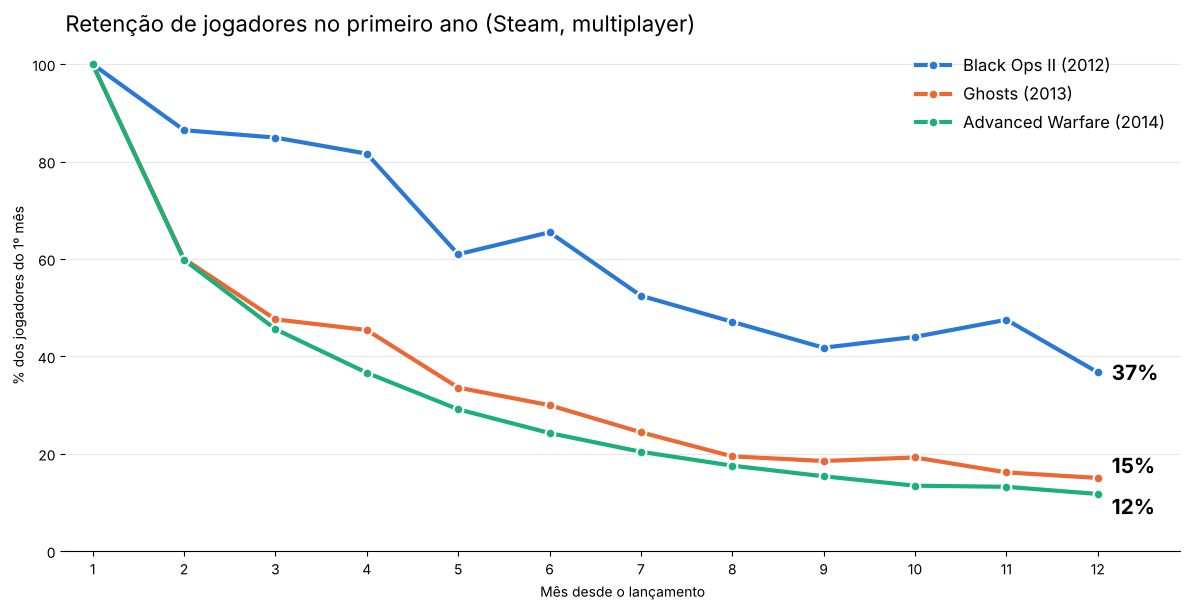

In [10]:
cores = {'Black Ops II': '#2a78d6', 'Ghosts': '#eb6834', 'Advanced Warfare': '#1baf7a'}
anos = {'Black Ops II': 2012, 'Ghosts': 2013, 'Advanced Warfare': 2014}
desloc = {'Black Ops II': 0, 'Ghosts': 9, 'Advanced Warfare': -9}

fig, ax = plt.subplots(figsize=(12, 6.2))
for jogo in JOGOS:
    d = mensal[mensal.jogo == jogo]
    ax.plot(d.mes, d['retencao_vs_mes1_%'], color=cores[jogo], lw=3, marker='o', ms=7,
            mec='white', mew=1.5, label=f'{jogo} ({anos[jogo]})')
    final = d['retencao_vs_mes1_%'].iloc[-1]
    ax.annotate(f'{final:.0f}%', (12, final), xytext=(10, desloc[jogo]), textcoords='offset points',
                va='center', fontsize=15, fontweight='bold')
ax.set_xticks(range(1, 13)); ax.set_xlim(0.7, 12.9); ax.set_ylim(0, 105)
ax.set_xlabel('Mês desde o lançamento'); ax.set_ylabel('% dos jogadores do 1º mês')
ax.grid(axis='y', alpha=0.3)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)
ax.legend(frameon=False, fontsize=12)
ax.set_title('Retenção de jogadores no primeiro ano (Steam, multiplayer)', loc='left', fontsize=16)
plt.tight_layout()
plt.savefig('grafico_retencao.png', dpi=200)
plt.show()

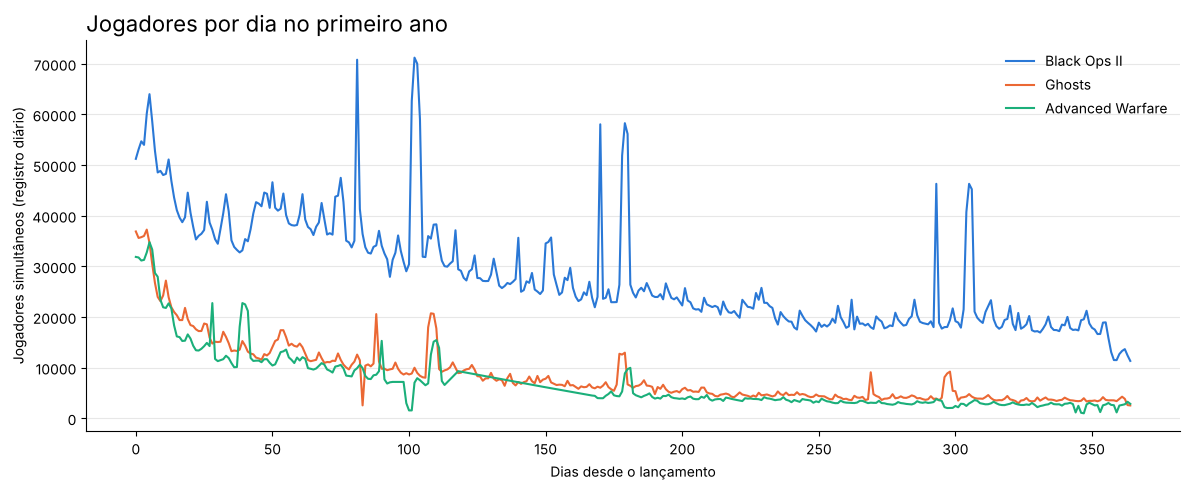

In [11]:
# Jogadores por dia no primeiro ano (dados brutos, mostrando os picos isolados)
fig, ax = plt.subplots(figsize=(12, 5))
for jogo in JOGOS:
    d = diario[diario.jogo == jogo].dropna(subset=['jogadores']).copy()
    lanc = pd.Timestamp(JOGOS[jogo]['lancamento'])
    d['dias_desde_lancamento'] = (d.data - lanc).dt.days
    ax.plot(d.dias_desde_lancamento, d.jogadores, color=cores[jogo], lw=1.5, label=jogo)
ax.set_xlabel('Dias desde o lançamento'); ax.set_ylabel('Jogadores simultâneos (registro diário)')
ax.grid(axis='y', alpha=0.3)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
ax.legend(frameon=False)
ax.set_title('Jogadores por dia no primeiro ano', loc='left', fontsize=16)
plt.tight_layout()
plt.show()

### Principais conclusões

1. **O público encolheu de um lançamento para o outro.** O Ghosts começou com cerca de metade dos jogadores do Black Ops II no 1º mês.
2. **A queda ficou quase duas vezes mais rápida.** O Black Ops II perdeu em média 8,5% dos jogadores por mês; Ghosts e Advanced Warfare perderam entre 14,7% e 16,6%.
3. **O Black Ops II segurou o público por muito mais tempo.** Levou 8 meses para perder metade dos jogadores, contra apenas 3 meses dos sucessores.
4. **Picos isolados no meio da queda** (por exemplo, mais de 70 mil jogadores no Black Ops II nos meses 3 e 4) podem estar ligados a fins de semana gratuitos, promoções ou novos conteúdos.

### Limitações
- Dados apenas da Steam (PC); na época, a maior parte do público jogava no Xbox 360 e no PlayStation 3.
- Os valores são registros diários do SteamDB, e não o total de pessoas que jogaram; servem para comparar os jogos entre si.
- Os resultados mostram **associação**, e não provam a causa da queda.

## 6. Implantação (Proposta)

Com base nos resultados, o projeto propõe o **relançamento do Black Ops II Remaster para PC**, com requisitos baixos, preço acessível em reais e opções de acessibilidade, voltado a ex-jogadores da era de ouro e a novos jogadores com computadores simples.

**Indicadores propostos:**

| Indicador | Como será calculado | Linha de base e meta |
|---|---|---|
| **Acesso:** jogadores com PCs abaixo do requisito dos CoDs atuais que conseguem rodar o remaster (%) | Jogadores com PC abaixo do requisito mínimo dos CoDs atuais que rodam o remaster ÷ total desses jogadores que tentaram × 100 | Base: 0%. Meta: 90% |
| **Resultado:** retenção no 12º mês (%) | Média de jogadores no mês 12 ÷ média no mês 1 × 100 | Base: 36,7% (Black Ops II original). Meta: acima de 40% |

A célula abaixo mostra como o indicador de **retenção no 12º mês** seria calculado com os dados do remaster, usando o mesmo método deste notebook.

In [12]:
def retencao_mes12(arquivo_csv, data_lancamento):
    """Calcula a retenção no 12º mês a partir de um CSV exportado do SteamDB."""
    df = pd.read_csv(arquivo_csv, sep=';', encoding='utf-8-sig', parse_dates=['DateTime'])
    lanc = pd.Timestamp(data_lancamento)
    medias = []
    for k in (0, 11):
        ini, fim = lanc + pd.DateOffset(months=k), lanc + pd.DateOffset(months=k + 1)
        medias.append(df[(df.DateTime >= ini) & (df.DateTime < fim)].Players.mean())
    return medias[1] / medias[0] * 100

# Conferência com o Black Ops II original (linha de base do indicador)
print(f"Retenção no 12º mês do Black Ops II original: {retencao_mes12('steamdb_chart_BO2.csv', '2012-11-12'):.1f}%")

Retenção no 12º mês do Black Ops II original: 36.7%
